In [1]:
!pip -q install tensorflow scikit-learn pillow requests
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from sklearn.model_selection import GroupShuffleSplit
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import random

# Set seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = 128
print("Setup complete.")

Setup complete.


In [2]:
DATA_DIR = r"C:\Users\len\Downloads\ajwa_medjool\ajwa+or+medjool"

# Verify the path exists and see what's inside
if not os.path.exists(DATA_DIR):
    print(f"ERROR: The path '{DATA_DIR}' does not exist. Please check your path.")
else:
    print(f"Found dataset at: {DATA_DIR}")
    print("Folders found:", os.listdir(DATA_DIR))

# Broad search for image files across any subdirectory layout
files = sorted(
    glob.glob(f"{DATA_DIR}/**/*.png", recursive=True) + 
    glob.glob(f"{DATA_DIR}/**/*.jpg", recursive=True) +
    glob.glob(f"{DATA_DIR}/**/*.PNG", recursive=True) + 
    glob.glob(f"{DATA_DIR}/**/*.JPG", recursive=True)
)

print("images found:", len(files))

Found dataset at: C:\Users\len\Downloads\ajwa_medjool\ajwa+or+medjool
Folders found: ['.DS_Store', 'Ajwa', 'AjwaOrMejdool.csv', 'Embedded images - Inception V3.csv', 'Embedded images - SqueezNet.csv', 'Embedded images - Vgg-16.csv', 'Embedded images - Vgg-19.csv', 'Medjool', 'README.md']
images found: 400


In [6]:
import os
import numpy as np
from PIL import Image

# Keep your existing FOLDER_FILTER
FOLDER_FILTER = None 

# 1. label function that only looks at the immediate parent folder
def label_of(path):
    parent_folder = os.path.basename(os.path.dirname(path)).lower()
    
    if "medjool" in parent_folder: return 1
    if "ajwa" in parent_folder: return 0
    
    filename = os.path.basename(path).lower()
    if "medjool" in filename: return 1
    if "ajwa" in filename: return 0
    
    return None

def load(path):
    img = Image.open(path)
    if img.mode in ("RGBA", "LA", "P"):
        img = img.convert("RGBA")
        bg = Image.new("RGBA", img.size, (255, 255, 255, 255))
        img = Image.alpha_composite(bg, img)
    img = img.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    return np.asarray(img, dtype=np.uint8)

# 2. Use os.walk to safely find files on Windows
paths = []
for root, dirs, files in os.walk(DATA_DIR):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            full_path = os.path.join(root, file)
            if FOLDER_FILTER is None or FOLDER_FILTER.lower() in full_path.lower():
                paths.append(full_path)

print(f"Total image paths found: {len(paths)}")

# 3. Assign labels
y = np.array([label_of(p) for p in paths])

# Filter out any paths where label couldn't be determined
valid_idx = y != None
paths = [paths[i] for i in range(len(paths)) if valid_idx[i]]
y = y[valid_idx].astype(int)

print(f"After filtering: {len(paths)} images")
print(f"Class counts -> Ajwa (0): {(y==0).sum()}, Medjool (1): {(y==1).sum()}")

# 4. Generate groups 
groups = np.array([os.path.dirname(p) for p in paths])

# 5. Load images into memory
X = np.stack([load(p) for p in paths])

print(f"Final X shape: {X.shape}")
print(f"Final y shape: {y.shape}")

Total image paths found: 200
After filtering: 200 images
Class counts -> Ajwa (0): 100, Medjool (1): 100
Final X shape: (200, 128, 128, 3)
Final y shape: (200,)


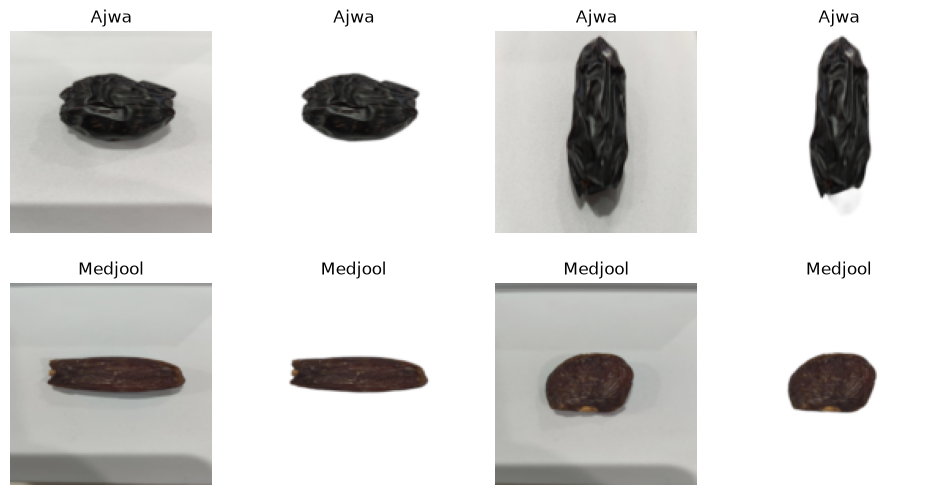

In [7]:
fig, ax = plt.subplots(2, 4, figsize=(12, 6))
for row, cls in enumerate([0, 1]):
    idx = np.where(y == cls)[0][:4]
    for a, i in zip(ax[row], idx):
        a.imshow(X[i]); a.axis("off"); a.set_title(["Ajwa", "Medjool"][cls])
plt.show()

In [9]:
from sklearn.model_selection import train_test_split

# 1. First split: 70% Train, 30% Temporary (Val + Test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, 
    test_size=0.30, 
    random_state=SEED, 
    stratify=y # Ensures equal Ajwa/Medjool ratio in both sets
)

# 2. Second split: Split the 30% Temporary into 15% Val and 15% Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, 
    test_size=0.50, 
    random_state=SEED, 
    stratify=y_temp
)

# 3. Print the counts to verify it worked
for name, labels in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:5s} n={len(labels):3d}  Ajwa={np.sum(labels==0):3d}  Medjool={np.sum(labels==1):3d}")

# 4. Create the TensorFlow datasets
BATCH = 16

def ds(X_data, y_data, train=False):
    d = tf.data.Dataset.from_tensor_slices((X_data, y_data.astype("float32")))
    if train: 
        d = d.shuffle(len(X_data), seed=SEED)
    return d.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = ds(X_train, y_train, train=True)
val_ds = ds(X_val, y_val)
test_ds = ds(X_test, y_test)

train n=140  Ajwa= 70  Medjool= 70
val   n= 30  Ajwa= 15  Medjool= 15
test  n= 30  Ajwa= 15  Medjool= 15
